In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns
import csv
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)
import sys
np.set_printoptions(threshold=sys.maxsize)

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

df = pd.read_csv(
    "Dataset_insuficiencia_renal_crnica.csv",
    sep=",",
    engine="python",
    quoting=csv.QUOTE_MINIMAL
)

print("Dataset Shape:", df.shape)

display(df.head())

print(df.columns.tolist())

display(df.dtypes.to_frame("dtype"))

print(df.memory_usage(deep=True).sum() / 1024, "KB")

df.info()

display(df.describe().T)

Dataset Shape: (15051, 21)


,Identificación del paciente,Edad,Presión arterial,Gravedad específica de la orina,Albúmina en orina,Azúcar en orina,Glóbulos rojos,Células de pus,Grupos de células de pus,Bacterias,Glucosa en sangre aleatoria,Urea en sangre,Creatinina sérica,Sodio en sangre,Potasio en sangre,Hemoglobina,Volumen corpuscular empaquetado,Recuento de glóbulos blancos,Recuento de glóbulos rojos,Apetito,Insuficiencia renal crónica
0,0,48,178,1010.00,2.00,2,anormal,anormal,presente,presente,298,195.00,9.08,124.00,6.00,8.00,25.00,11319,3.80,bajo,si
1,1,7,138,1014.00,1.00,4,anormal,anormal,presente,presente,187,111.00,7.88,133.00,6.80,11.00,27.00,11018,2.90,bajo,si
2,2,62,165,1014.00,2.00,5,anormal,anormal,presente,presente,286,149.00,12.89,130.00,6.00,8.00,27.00,5479,4.40,bajo,si
3,3,48,141,1007.00,4.00,4,anormal,anormal,presente,presente,165,98.00,5.02,133.00,5.80,11.00,35.00,7817,3.20,bajo,si
4,4,51,175,1015.00,4.00,5,anormal,anormal,presente,presente,179,152.00,7.32,132.00,6.80,9.00,30.00,3055,3.90,bajo,si


['Identificación del paciente', 'Edad', 'Presión arterial', 'Gravedad específica de la orina', 'Albúmina en orina', 'Azúcar en orina', 'Glóbulos rojos', 'Células de pus', 'Grupos de células de pus', 'Bacterias', 'Glucosa en sangre aleatoria', 'Urea en sangre', 'Creatinina sérica', 'Sodio en sangre', 'Potasio en sangre', 'Hemoglobina', 'Volumen corpuscular empaquetado', 'Recuento de glóbulos blancos', 'Recuento de glóbulos rojos', 'Apetito', 'Insuficiencia renal crónica']


,dtype
Identificación del paciente,int64
Edad,int64
Presión arterial,int64
Gravedad específica de la orina,float64
Albúmina en orina,float64
Azúcar en orina,int64
Glóbulos rojos,str
Células de pus,str
Grupos de células de pus,str
Bacterias,str


6581.4453125 KB
<class 'pandas.DataFrame'>
RangeIndex: 15051 entries, 0 to 15050
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Identificación del paciente      15051 non-null  int64  
 1   Edad                             15051 non-null  int64  
 2   Presión arterial                 15051 non-null  int64  
 3   Gravedad específica de la orina  15051 non-null  float64
 4   Albúmina en orina                15051 non-null  float64
 5   Azúcar en orina                  15051 non-null  int64  
 6   Glóbulos rojos                   15051 non-null  str    
 7   Células de pus                   15051 non-null  str    
 8   Grupos de células de pus         15042 non-null  str    
 9   Bacterias                        15045 non-null  str    
 10  Glucosa en sangre aleatoria      15051 non-null  int64  
 11  Urea en sangre                   15051 non-null  float64
 12  Creatinina sé

,count,mean,std,min,25%,50%,75%,max
Identificación del paciente,15051.00,7525.00,4344.99,0.00,3762.50,7525.00,11287.50,15050.00
Edad,15051.00,52.10,17.55,2.00,45.00,55.00,65.00,90.00
Presión arterial,15051.00,93.23,19.91,50.00,80.00,94.00,107.00,180.00
Gravedad específica de la orina,15051.00,541.34,502.98,10.00,12.63,1015.00,1020.00,1025.00
Albúmina en orina,15051.00,228.36,314.22,0.00,0.00,1.00,452.40,989.90
Azúcar en orina,15051.00,154.32,248.58,0.00,0.00,1.00,200.00,1000.00
Glucosa en sangre aleatoria,15051.00,157.61,62.35,70.00,105.00,139.00,208.00,300.00
Urea en sangre,15051.00,59.65,42.51,10.00,25.00,40.00,93.55,200.00
Creatinina sérica,15042.00,3.22,5.48,0.40,0.93,1.40,3.25,76.00
Sodio en sangre,15051.00,138.58,5.82,120.00,135.00,139.00,143.00,150.00


In [3]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(3)
})

display(
    missing_summary[
        missing_summary["Missing_Count"] > 0
    ].sort_values("Missing_Count", ascending=False)
)

,Missing_Count,Missing_Percentage
Grupos de células de pus,9,0.06
Creatinina sérica,9,0.06
Bacterias,6,0.04
Insuficiencia renal crónica,2,0.01
Apetito,1,0.01


In [4]:
id_col = "Identificación del paciente"

print("Exact duplicate rows:", df.duplicated().sum())

print("Duplicate patient IDs:", df[id_col].duplicated().sum())

print("Unique patient IDs:", df[id_col].nunique())

print("Missing patient IDs:", df[id_col].isna().sum())

print("\nFirst 10 IDs:")
print(df[id_col].head(10).tolist())

print("\nLast 10 IDs:")
print(df[id_col].tail(10).tolist())

print(
    "\nID follows row sequence:",
    df[id_col].reset_index(drop=True).equals(
        pd.Series(np.arange(len(df)))
    )
)

Exact duplicate rows: 0
Duplicate patient IDs: 0
Unique patient IDs: 15051
Missing patient IDs: 0

First 10 IDs:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Last 10 IDs:
[15041, 15042, 15043, 15044, 15045, 15046, 15047, 15048, 15049, 15050]

ID follows row sequence: True


In [5]:
pd.set_option('display.max_rows', None)      
pd.set_option('display.max_columns', None)   
pd.set_option('display.max_colwidth', None)

categorical_cols = [
    "Glóbulos rojos",
    "Células de pus",
    "Grupos de células de pus",
    "Bacterias",
    "Apetito",
    "Insuficiencia renal crónica"
]

for col in categorical_cols:
    print(f"\n{'=' * 50}")
    print(df[col].value_counts(dropna=False).to_string())


Glóbulos rojos
normal     7690
anormal    7361

Células de pus
normal     7655
anormal    7396

Grupos de células de pus
ausente     12596
presente     2446
NaN             9

Bacterias
ausente     13732
presente     1313
NaN             6

Apetito
bueno    8425
bajo     6625
NaN         1

Insuficiencia renal crónica
no     7696
si     7353
NaN       2


In [6]:
check_cols = [
    "Edad",
    "Presión arterial",
    "Gravedad específica de la orina",
    "Albúmina en orina",
    "Azúcar en orina",
    "Glucosa en sangre aleatoria",
    "Urea en sangre",
    "Creatinina sérica",
    "Sodio en sangre",
    "Potasio en sangre",
    "Hemoglobina",
    "Volumen corpuscular empaquetado",
    "Recuento de glóbulos blancos",
    "Recuento de glóbulos rojos"
]

display(
    df[check_cols].agg(["min", "max"]).T
)

,min,max
Edad,2.00,90.00
Presión arterial,50.00,180.00
Gravedad específica de la orina,10.00,1025.00
Albúmina en orina,0.00,989.90
Azúcar en orina,0.00,1000.00
Glucosa en sangre aleatoria,70.00,300.00
Urea en sangre,10.00,200.00
Creatinina sérica,0.40,76.00
Sodio en sangre,120.00,150.00
Potasio en sangre,3.50,7.50


In [7]:
for col in check_cols:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print("Smallest values:")
    print(df[col].nsmallest(10).tolist())
    print("Largest values:")
    print(df[col].nlargest(10).tolist())


Edad
Unique values: 75
Smallest values:
[2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Largest values:
[90, 90, 90, 90, 90, 90, 90, 90, 90, 90]

Presión arterial
Unique values: 93
Smallest values:
[50, 50, 50, 50, 50, 50, 50, 50, 50, 50]
Largest values:
[180, 180, 180, 180, 180, 180, 180, 180, 180, 180]

Gravedad específica de la orina
Unique values: 522
Smallest values:
[10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0]
Largest values:
[1025.0, 1025.0, 1025.0, 1025.0, 1025.0, 1025.0, 1025.0, 1025.0, 1025.0, 1025.0]

Albúmina en orina
Unique values: 5051
Smallest values:
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Largest values:
[989.9, 989.8, 989.8, 989.8, 989.6, 989.5, 989.4, 989.3, 989.1, 989.0]

Azúcar en orina
Unique values: 959
Smallest values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Largest values:
[1000, 1000, 999, 999, 999, 999, 999, 998, 998, 998]

Glucosa en sangre aleatoria
Unique values: 231
Smallest values:
[70, 70, 70, 70, 70, 70, 70, 70, 70, 70]
Largest values:
[300, 300, 300

In [8]:
specific_gravity = "Gravedad específica de la orina"
albumin = "Albúmina en orina"
sugar = "Azúcar en orina"
creatinine = "Creatinina sérica"

sg = df[specific_gravity]


print("Specific gravity below 1000:")
print((sg < 1000).sum())

print("\nMost frequent values below 1000:")
print(
    sg[sg < 1000]
    .value_counts()
    .sort_index()
    .head(30)
)

print("\nSpecific gravity values around 1000:")
print(
    sg[(sg >= 1000) & (sg <= 1030)]
    .value_counts()
    .sort_index()
)


for col in [albumin, sugar, creatinine]:
    print(f"\n{'=' * 50}")
    print(col)
    print("Unique values:", df[col].nunique())
    print("Percentiles:")
    print(
        df[col].quantile(
            [0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]
        )
    )

Specific gravity below 1000:
7148

Most frequent values below 1000:
Gravedad específica de la orina
10.00    11
10.01    10
10.02    18
10.03    16
10.04    11
10.05    24
10.06    18
10.07     9
10.08    15
10.09    11
10.10    16
10.11    13
10.12    12
10.13    13
10.14    13
10.15    16
10.16    13
10.17    12
10.18    13
10.19    12
10.20    17
10.21    18
10.22    12
10.23    17
10.24    18
10.25    28
10.26    12
10.27    13
10.28    14
10.29     9
Name: count, dtype: int64

Specific gravity values around 1000:
Gravedad específica de la orina
1005.00     29
1006.00     13
1007.00     22
1008.00     17
1009.00     22
1010.00     25
1011.00     16
1012.00     27
1013.00     27
1014.00     24
1015.00    748
1016.00    653
1017.00    765
1018.00    676
1019.00    684
1020.00    696
1021.00    699
1022.00    690
1023.00    707
1024.00    686
1025.00    677
Name: count, dtype: int64

Albúmina en orina
Unique values: 5051
Percentiles:
0.00     0.00
0.01     0.00
0.05     0.00
0.25     

In [9]:
specific_gravity = "Gravedad específica de la orina"

sg = df[specific_gravity]

print("Minimum value below 1000:")
print(sg[sg < 1000].min())

print("\nMaximum value below 1000:")
print(sg[sg < 1000].max())

print("\nLargest 30 unique values below 1000:")
print(sorted(sg[sg < 1000].dropna().unique())[-30:])

print("\nValues below 1000 outside the range 10 to 11:")
print(sg[(sg < 1000) & ((sg < 10) | (sg >= 11))]
      .value_counts().sort_index())

print("\nSample rows with values below 1000:")
print(
    df.loc[sg < 1000, [
        "Identificación del paciente",
        specific_gravity,
        "Insuficiencia renal crónica"
    ]].head(15).to_string(index=False)
)

Minimum value below 1000:
10.0

Maximum value below 1000:
15.0

Largest 30 unique values below 1000:
[np.float64(14.71), np.float64(14.72), np.float64(14.73), np.float64(14.74), np.float64(14.75), np.float64(14.76), np.float64(14.77), np.float64(14.78), np.float64(14.79), np.float64(14.8), np.float64(14.81), np.float64(14.82), np.float64(14.83), np.float64(14.84), np.float64(14.85), np.float64(14.86), np.float64(14.87), np.float64(14.88), np.float64(14.89), np.float64(14.9), np.float64(14.91), np.float64(14.92), np.float64(14.93), np.float64(14.94), np.float64(14.95), np.float64(14.96), np.float64(14.97), np.float64(14.98), np.float64(14.99), np.float64(15.0)]

Values below 1000 outside the range 10 to 11:
Gravedad específica de la orina
11.00    13
11.01    19
11.02    14
11.03    16
11.04     8
11.05    11
11.06    19
11.07    17
11.08    20
11.09     9
11.10     9
11.11    14
11.12    18
11.13     9
11.14    18
11.15    19
11.16    15
11.17    13
11.18    12
11.19    18
11.20    18


In [10]:
specific_gravity = "Gravedad específica de la orina"
target = "Insuficiencia renal crónica"

print("Specific gravity summary by target:")
print(
    df.groupby(target, dropna=False)[specific_gravity]
      .agg(["count", "min", "median", "max", "nunique"])
)

print("\nTarget distribution by specific gravity format:")
print(
    df.assign(
        sg_format=df[specific_gravity].apply(
            lambda x: "Missing" if pd.isna(x)
            else "Below 1000" if x < 1000
            else "1000 or above"
        )
    )
    .groupby(["sg_format", target], dropna=False)
    .size()
    .unstack(fill_value=0)
)

print("\nMost frequent unique values:")
print(df[specific_gravity].value_counts().head(15))

Specific gravity summary by target:
                             count   min  median     max  nunique
Insuficiencia renal crónica                                      
no                            7696 10.00 1016.00 1025.00      516
si                            7353 10.00   14.95 1025.00      521
NaN                              2 13.23   13.59   13.95        2

Target distribution by specific gravity format:
Insuficiencia renal crónica    no    si  NaN
sg_format                                   
1000 or above                4261  3642    0
Below 1000                   3435  3711    2

Most frequent unique values:
Gravedad específica de la orina
1017.00    765
1015.00    748
1023.00    707
1021.00    699
1020.00    696
1022.00    690
1024.00    686
1019.00    684
1025.00    677
1018.00    676
1016.00    653
1005.00     29
10.25       28
1013.00     27
1012.00     27
Name: count, dtype: int64


In [11]:
specific_gravity = "Gravedad específica de la orina"
patient_id = "Identificación del paciente"

sg = df[specific_gravity]

ranges = {
    "10.00 to below 11": (sg >= 10) & (sg < 11),
    "11 to 15": (sg >= 11) & (sg <= 15),
    "Above 15 and below 1000": (sg > 15) & (sg < 1000),
    "1000 to below 1005": (sg >= 1000) & (sg < 1005),
    "1005 to 1025": (sg >= 1005) & (sg <= 1025),
    "Missing": sg.isna()
}

for label, mask in ranges.items():
    print(f"\n{label}: {mask.sum()} rows")
    print("Patient ID range:")
    print(df.loc[mask, patient_id].agg(["min", "max"]).to_dict())

print("\nRows around ID 7890:")
print(
    df.loc[df[patient_id].between(7887, 7897),
           [patient_id, specific_gravity, "Insuficiencia renal crónica"]]
      .to_string(index=False)
)


10.00 to below 11: 1429 rows
Patient ID range:
{'min': 7898, 'max': 15036}

11 to 15: 5719 rows
Patient ID range:
{'min': 7892, 'max': 15039}

Above 15 and below 1000: 0 rows
Patient ID range:
{'min': nan, 'max': nan}

1000 to below 1005: 0 rows
Patient ID range:
{'min': nan, 'max': nan}

1005 to 1025: 7903 rows
Patient ID range:
{'min': 0, 'max': 15050}

Missing: 0 rows
Patient ID range:
{'min': nan, 'max': nan}

Rows around ID 7890:
 Identificación del paciente  Gravedad específica de la orina Insuficiencia renal crónica
                        7887                          1018.00                          si
                        7888                          1018.00                          si
                        7889                          1020.00                          si
                        7890                          1018.00                          si
                        7891                          1018.00                          si
                    

In [12]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head().to_string())

print("\nLast 5 rows:")
print(df.tail().to_string())

Dataset shape: (15051, 21)

Column names:
['Identificación del paciente', 'Edad', 'Presión arterial', 'Gravedad específica de la orina', 'Albúmina en orina', 'Azúcar en orina', 'Glóbulos rojos', 'Células de pus', 'Grupos de células de pus', 'Bacterias', 'Glucosa en sangre aleatoria', 'Urea en sangre', 'Creatinina sérica', 'Sodio en sangre', 'Potasio en sangre', 'Hemoglobina', 'Volumen corpuscular empaquetado', 'Recuento de glóbulos blancos', 'Recuento de glóbulos rojos', 'Apetito', 'Insuficiencia renal crónica']

First 5 rows:
   Identificación del paciente  Edad  Presión arterial  Gravedad específica de la orina  Albúmina en orina  Azúcar en orina Glóbulos rojos Células de pus Grupos de células de pus Bacterias  Glucosa en sangre aleatoria  Urea en sangre  Creatinina sérica  Sodio en sangre  Potasio en sangre  Hemoglobina  Volumen corpuscular empaquetado  Recuento de glóbulos blancos  Recuento de glóbulos rojos Apetito Insuficiencia renal crónica
0                            0    48  

In [13]:
patient_id = "Identificación del paciente"
specific_gravity = "Gravedad específica de la orina"
albumin = "Albúmina en orina"
sugar = "Azúcar en orina"

df["ID_range"] = pd.cut(
    df[patient_id],
    bins=[-1, 3000, 6000, 9000, 12000, 15051],
    labels=["0–3000", "3001–6000", "6001–9000",
            "9001–12000", "12001–15050"]
)

for col in [specific_gravity, albumin, sugar]:
    print(f"\n{'=' * 55}")
    print(col)

    if col == specific_gravity:
        unusual = df[col] < 1000
    else:
        unusual = df[col] > 5

    print(
        df.assign(unusual=unusual)
          .groupby("ID_range", observed=False)["unusual"]
          .agg(["sum", "count"])
    )


Gravedad específica de la orina
              sum  count
ID_range                
0–3000          0   3001
3001–6000       0   3000
6001–9000    1109   3000
9001–12000   3000   3000
12001–15050  3039   3050

Albúmina en orina
              sum  count
ID_range                
0–3000          0   3001
3001–6000       0   3000
6001–9000    1109   3000
9001–12000   2929   3000
12001–15050  3039   3050

Azúcar en orina
              sum  count
ID_range                
0–3000          0   3001
3001–6000       0   3000
6001–9000    1109   3000
9001–12000   3000   3000
12001–15050  3039   3050


In [14]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

numeric_cols = [
    col for col in numeric_cols
    if col not in [
        "Identificación del paciente",
        "ID_range"
    ]
]

comparison = pd.DataFrame({
    "First 6000 rows mean": df.iloc[:6000][numeric_cols].mean(),
    "Last 9051 rows mean": df.iloc[6000:][numeric_cols].mean(),
    "First 6000 rows median": df.iloc[:6000][numeric_cols].median(),
    "Last 9051 rows median": df.iloc[6000:][numeric_cols].median()
})

print(comparison.round(2).to_string())

                                 First 6000 rows mean  Last 9051 rows mean  First 6000 rows median  Last 9051 rows median
Edad                                            52.18                52.05                   55.00                  55.00
Presión arterial                               107.02                84.09                  106.00                  80.00
Gravedad específica de la orina               1019.57               224.32                 1020.00                  13.16
Albúmina en orina                                0.61               379.34                    1.00                 343.00
Azúcar en orina                                  0.60               256.22                    1.00                 162.00
Glucosa en sangre aleatoria                    109.89               189.24                  107.00                 193.00
Urea en sangre                                  28.69                80.18                   26.00                  79.90
Creatinina sérica       

In [15]:
target = "Insuficiencia renal crónica"

target_counts = pd.crosstab(
    df["ID_range"],
    df[target],
    margins=False
)

target_percentages = pd.crosstab(
    df["ID_range"],
    df[target],
    normalize="index"
).mul(100).round(2)

print("Target counts by ID range:")
print(target_counts)

print("\nTarget percentages by ID range:")
print(target_percentages)

Target counts by ID range:
Insuficiencia renal crónica    no    si
ID_range                               
0–3000                       1591  1410
3001–6000                    1282  1718
6001–9000                    1611  1388
9001–12000                    334  2665
12001–15050                  2878   172

Target percentages by ID range:
Insuficiencia renal crónica    no    si
ID_range                               
0–3000                      53.02 46.98
3001–6000                   42.73 57.27
6001–9000                   53.72 46.28
9001–12000                  11.14 88.86
12001–15050                 94.36  5.64


In [16]:
features = [
    "Edad",
    "Presión arterial",
    "Gravedad específica de la orina",
    "Albúmina en orina",
    "Azúcar en orina",
    "Glucosa en sangre aleatoria",
    "Urea en sangre",
    "Creatinina sérica",
    "Hemoglobina",
    "Insuficiencia renal crónica"
]

print("Exact duplicate medical records (excluding Patient ID):")
print(df.duplicated(subset=features).sum())

print("\nTarget distribution in the first and last 100 rows:")
print(
    pd.crosstab(
        pd.Series(
            ["First 100"] * 100 + ["Last 100"] * 100,
            name="Group"
        ),
        pd.concat([
            df["Insuficiencia renal crónica"].iloc[:100].reset_index(drop=True),
            df["Insuficiencia renal crónica"].iloc[-100:].reset_index(drop=True)
        ], ignore_index=True)
    )
)

Exact duplicate medical records (excluding Patient ID):
1

Target distribution in the first and last 100 rows:
Insuficiencia renal crónica  no   si
Group                               
First 100                     0  100
Last 100                     91    9


In [17]:
target = "Insuficiencia renal crónica"

for start in range(0, len(df), 1000):
    end = min(start + 1000, len(df))
    block = df.iloc[start:end]

    print(f"\nRows {start} to {end - 1}")
    print(block[target].value_counts(normalize=True).mul(100).round(2))


Rows 0 to 999
Insuficiencia renal crónica
no   75.20
si   24.80
Name: proportion, dtype: float64

Rows 1000 to 1999
Insuficiencia renal crónica
no   64.30
si   35.70
Name: proportion, dtype: float64

Rows 2000 to 2999
Insuficiencia renal crónica
si   80.40
no   19.60
Name: proportion, dtype: float64

Rows 3000 to 3999
Insuficiencia renal crónica
si   80.60
no   19.40
Name: proportion, dtype: float64

Rows 4000 to 4999
Insuficiencia renal crónica
si   88.40
no   11.60
Name: proportion, dtype: float64

Rows 5000 to 5999
Insuficiencia renal crónica
no   97.10
si    2.90
Name: proportion, dtype: float64

Rows 6000 to 6999
Insuficiencia renal crónica
no   75.60
si   24.40
Name: proportion, dtype: float64

Rows 7000 to 7999
Insuficiencia renal crónica
no   62.20
si   37.80
Name: proportion, dtype: float64

Rows 8000 to 8999
Insuficiencia renal crónica
si   76.58
no   23.42
Name: proportion, dtype: float64

Rows 9000 to 9999
Insuficiencia renal crónica
si   66.67
no   33.33
Name: proportion,

In [18]:
target = "Insuficiencia renal crónica"
patient_id = "Identificación del paciente"

print(
    df.groupby("ID_range", observed=False)[target]
      .value_counts(normalize=True)
      .mul(100)
      .round(2)
)

ID_range     Insuficiencia renal crónica
0–3000       no                            53.02
             si                            46.98
3001–6000    si                            57.27
             no                            42.73
6001–9000    no                            53.72
             si                            46.28
9001–12000   si                            88.86
             no                            11.14
12001–15050  no                            94.36
             si                             5.64
Name: proportion, dtype: float64


In [19]:
print("First 10 patient IDs:")
print(df["Identificación del paciente"].head(10).tolist())

print("\nLast 10 patient IDs:")
print(df["Identificación del paciente"].tail(10).tolist())

print("\nCorrelation between Patient ID and selected numerical features:")
print(
    df[
        [
            "Identificación del paciente",
            "Edad",
            "Presión arterial",
            "Glucosa en sangre aleatoria",
            "Urea en sangre",
            "Hemoglobina"
        ]
    ].corr(numeric_only=True)["Identificación del paciente"].round(3)
)

First 10 patient IDs:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

Last 10 patient IDs:
[15041, 15042, 15043, 15044, 15045, 15046, 15047, 15048, 15049, 15050]

Correlation between Patient ID and selected numerical features:
Identificación del paciente    1.00
Edad                          -0.00
Presión arterial              -0.64
Glucosa en sangre aleatoria    0.65
Urea en sangre                 0.65
Hemoglobina                   -0.66
Name: Identificación del paciente, dtype: float64


In [20]:
numeric_cols = df.select_dtypes(include="number").columns.drop(
    "Identificación del paciente",
    errors="ignore"
)


print("Descriptive Statistics:")
display(df[numeric_cols].describe().T)


q1 = df[numeric_cols].quantile(0.25)
q3 = df[numeric_cols].quantile(0.75)
iqr = q3 - q1

iqr_summary = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Lower Bound": q1 - 1.5 * iqr,
    "Upper Bound": q3 + 1.5 * iqr,
    "Min": df[numeric_cols].min(),
    "Max": df[numeric_cols].max()
})

display(iqr_summary.round(2))

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Edad,15051.00,52.10,17.55,2.00,45.00,55.00,65.00,90.00
Presión arterial,15051.00,93.23,19.91,50.00,80.00,94.00,107.00,180.00
Gravedad específica de la orina,15051.00,541.34,502.98,10.00,12.63,1015.00,1020.00,1025.00
Albúmina en orina,15051.00,228.36,314.22,0.00,0.00,1.00,452.40,989.90
Azúcar en orina,15051.00,154.32,248.58,0.00,0.00,1.00,200.00,1000.00
Glucosa en sangre aleatoria,15051.00,157.61,62.35,70.00,105.00,139.00,208.00,300.00
Urea en sangre,15051.00,59.65,42.51,10.00,25.00,40.00,93.55,200.00
Creatinina sérica,15042.00,3.22,5.48,0.40,0.93,1.40,3.25,76.00
Sodio en sangre,15051.00,138.58,5.82,120.00,135.00,139.00,143.00,150.00
Potasio en sangre,15051.00,5.38,0.86,3.50,4.79,5.40,6.09,7.50


,Q1,Q3,IQR,Lower Bound,Upper Bound,Min,Max
Edad,45.00,65.00,20.00,15.00,95.00,2.00,90.00
Presión arterial,80.00,107.00,27.00,39.50,147.50,50.00,180.00
Gravedad específica de la orina,12.63,1020.00,1007.37,-1498.42,2531.06,10.00,1025.00
Albúmina en orina,0.00,452.40,452.40,-678.60,1131.00,0.00,989.90
Azúcar en orina,0.00,200.00,200.00,-300.00,500.00,0.00,1000.00
Glucosa en sangre aleatoria,105.00,208.00,103.00,-49.50,362.50,70.00,300.00
Urea en sangre,25.00,93.55,68.55,-77.82,196.38,10.00,200.00
Creatinina sérica,0.93,3.25,2.32,-2.54,6.73,0.40,76.00
Sodio en sangre,135.00,143.00,8.00,123.00,155.00,120.00,150.00
Potasio en sangre,4.79,6.09,1.30,2.84,8.04,3.50,7.50


<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b521122a50>,
 'caps': [<matplotlib.lines.Line2D at 0x2b521122cf0>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b521122900>],
 'medians': [<matplotlib.lines.Line2D at 0x2b521122f90>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b5211230e0>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Edad')

Text(0.5, 0, 'Edad')

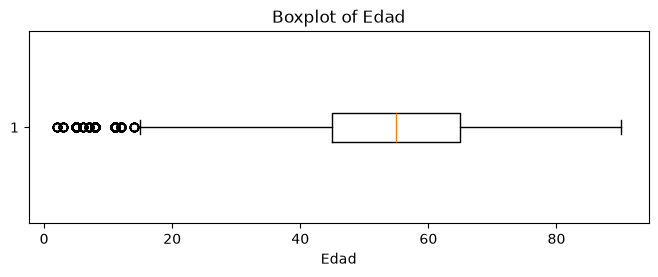

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b5216d9be0>,
 'caps': [<matplotlib.lines.Line2D at 0x2b5216d9e80>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b5216d9a90>],
 'medians': [<matplotlib.lines.Line2D at 0x2b5216da120>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b5216da270>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Presión arterial')

Text(0.5, 0, 'Presión arterial')

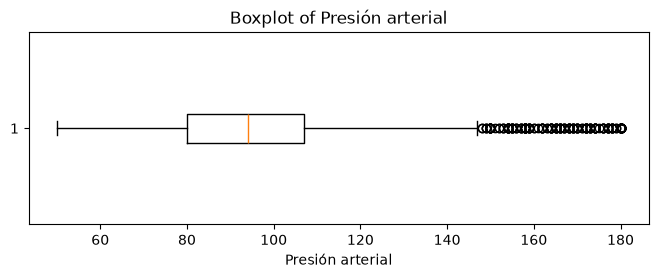

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b5220a1550>,
 'caps': [<matplotlib.lines.Line2D at 0x2b5220a17f0>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b5220a1400>],
 'medians': [<matplotlib.lines.Line2D at 0x2b5220a1a90>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b5220a1be0>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Gravedad específica de la orina')

Text(0.5, 0, 'Gravedad específica de la orina')

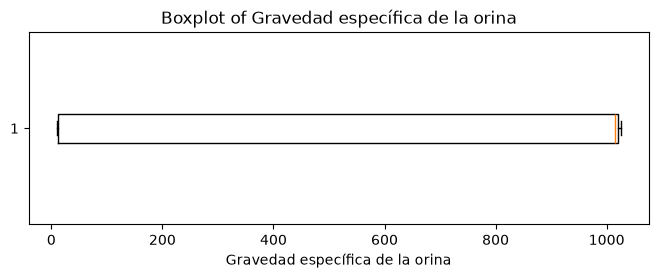

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b52536cad0>,
 'caps': [<matplotlib.lines.Line2D at 0x2b52536cd70>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b52536c980>],
 'medians': [<matplotlib.lines.Line2D at 0x2b52536d010>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b52536d160>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Albúmina en orina')

Text(0.5, 0, 'Albúmina en orina')

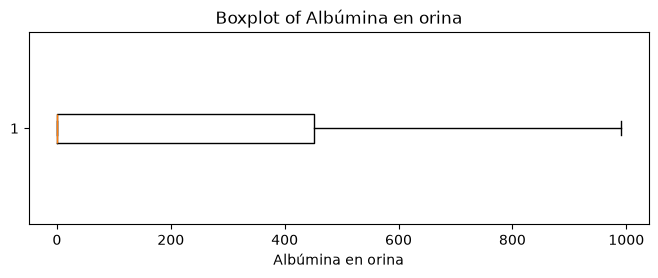

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b5253d8050>,
 'caps': [<matplotlib.lines.Line2D at 0x2b5253d82f0>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b52536fe00>],
 'medians': [<matplotlib.lines.Line2D at 0x2b5220a1550>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b5220a16a0>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Azúcar en orina')

Text(0.5, 0, 'Azúcar en orina')

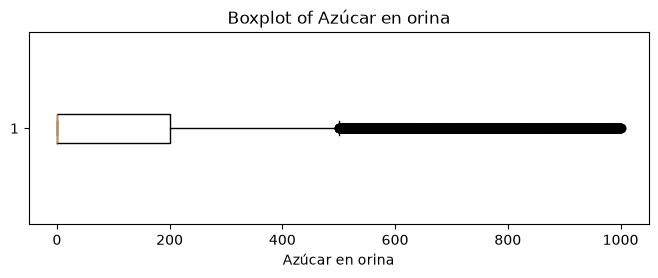

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b5220a34d0>,
 'caps': [<matplotlib.lines.Line2D at 0x2b5220a3230>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b5220a2e40>],
 'medians': [<matplotlib.lines.Line2D at 0x2b521122900>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b521122a50>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Glucosa en sangre aleatoria')

Text(0.5, 0, 'Glucosa en sangre aleatoria')

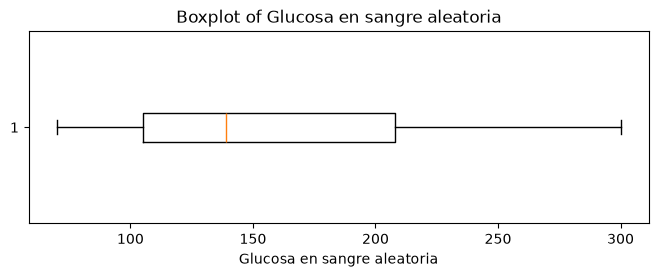

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b521c802f0>,
 'caps': [<matplotlib.lines.Line2D at 0x2b521c80830>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b521c801a0>],
 'medians': [<matplotlib.lines.Line2D at 0x2b521c80590>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b521c80c20>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Urea en sangre')

Text(0.5, 0, 'Urea en sangre')

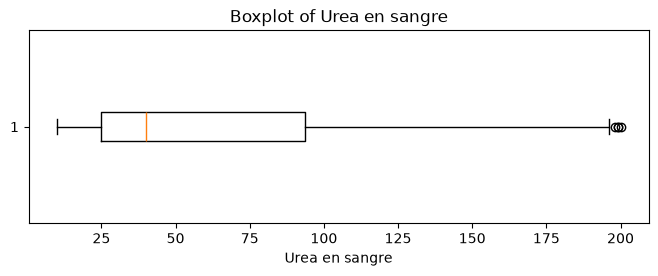

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b5213bdfd0>,
 'caps': [<matplotlib.lines.Line2D at 0x2b5213bcd70>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b5213bd550>],
 'medians': [<matplotlib.lines.Line2D at 0x2b5213bc590>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b521b12900>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Creatinina sérica')

Text(0.5, 0, 'Creatinina sérica')

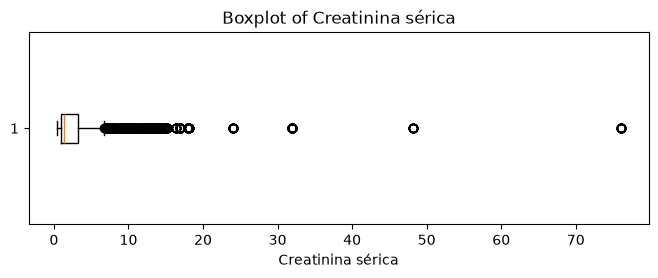

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b5253da120>,
 'caps': [<matplotlib.lines.Line2D at 0x2b5253da3c0>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b5253d9fd0>],
 'medians': [<matplotlib.lines.Line2D at 0x2b5253da660>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b5253da7b0>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Sodio en sangre')

Text(0.5, 0, 'Sodio en sangre')

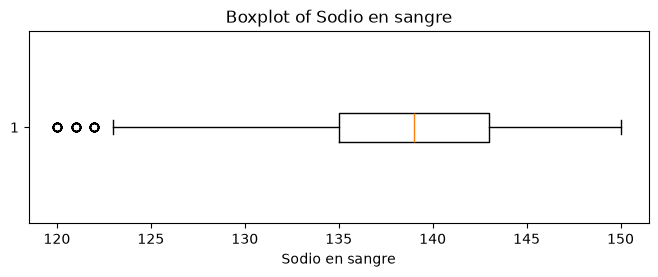

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b521fb1a90>,
 'caps': [<matplotlib.lines.Line2D at 0x2b521fb1d30>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b521fb1940>],
 'medians': [<matplotlib.lines.Line2D at 0x2b521fb1fd0>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b521fb2120>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Potasio en sangre')

Text(0.5, 0, 'Potasio en sangre')

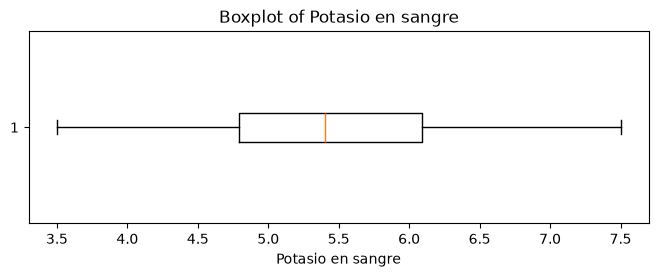

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b520f3dbe0>,
 'caps': [<matplotlib.lines.Line2D at 0x2b520f3de80>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b520f3da90>],
 'medians': [<matplotlib.lines.Line2D at 0x2b520f3e120>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b520f3e270>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Hemoglobina')

Text(0.5, 0, 'Hemoglobina')

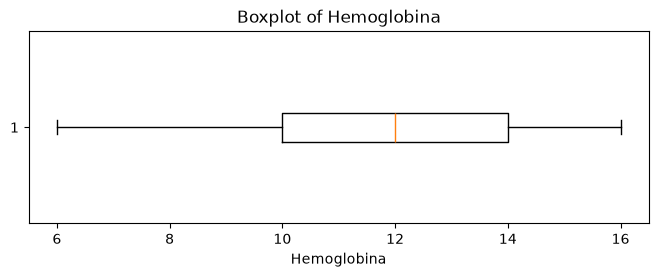

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b525439160>,
 'caps': [<matplotlib.lines.Line2D at 0x2b525439400>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b525439010>],
 'medians': [<matplotlib.lines.Line2D at 0x2b5254396a0>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b5254397f0>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Volumen corpuscular empaquetado')

Text(0.5, 0, 'Volumen corpuscular empaquetado')

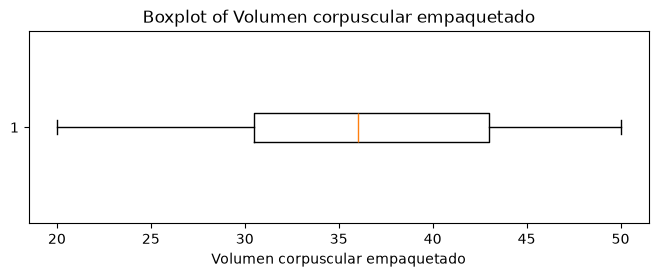

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b5254acad0>,
 'caps': [<matplotlib.lines.Line2D at 0x2b5254acd70>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b5254ac980>],
 'medians': [<matplotlib.lines.Line2D at 0x2b5254ad010>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b5254ad160>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Recuento de glóbulos blancos')

Text(0.5, 0, 'Recuento de glóbulos blancos')

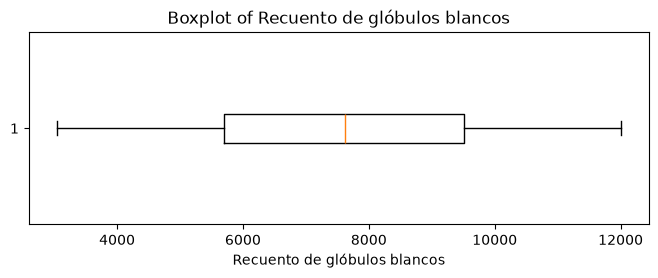

<Figure size 800x250 with 0 Axes>

C:\Users\mg050\AppData\Local\Temp\ipykernel_3448\2733230147.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


{'whiskers': [<matplotlib.lines.Line2D at 0x2b525438ec0>,
 'caps': [<matplotlib.lines.Line2D at 0x2b525439d30>,
 'boxes': [<matplotlib.lines.Line2D at 0x2b525439940>],
 'medians': [<matplotlib.lines.Line2D at 0x2b525439a90>],
 'fliers': [<matplotlib.lines.Line2D at 0x2b52543a120>],
 'means': []}

Text(0.5, 1.0, 'Boxplot of Recuento de glóbulos rojos')

Text(0.5, 0, 'Recuento de glóbulos rojos')

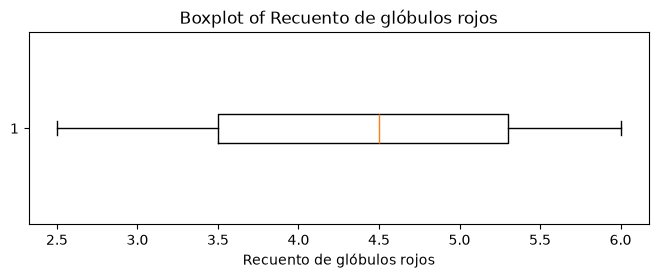

In [22]:
numeric_cols = df.select_dtypes(include="number").columns.drop(
    "Identificación del paciente",
    errors="ignore"
)

for col in numeric_cols:
    plt.figure(figsize=(8, 2.5))
    plt.boxplot(df[col].dropna(), vert=False )
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

In [23]:
outlier_results = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = df[col].notna() & (
        (df[col] < lower) | (df[col] > upper)
    )

    outlier_results.append({
        "Column": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": int(mask.sum()),
        "Outlier Percentage": round(
            mask.sum() / df[col].notna().sum() * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary.round(2))

,Column,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Edad,15.00,95.00,850,5.65
1,Presión arterial,39.50,147.50,200,1.33
2,Gravedad específica de la orina,-1498.42,2531.06,0,0.00
3,Albúmina en orina,-678.60,1131.00,0,0.00
4,Azúcar en orina,-300.00,500.00,1809,12.02
5,Glucosa en sangre aleatoria,-49.50,362.50,0,0.00
6,Urea en sangre,-77.82,196.38,4,0.03
7,Creatinina sérica,-2.54,6.73,1536,10.21
8,Sodio en sangre,123.00,155.00,52,0.35
9,Potasio en sangre,2.84,8.04,0,0.00


In [24]:
cols_to_check = [
    "Edad",
    "Presión arterial",
    "Azúcar en orina",
    "Creatinina sérica"
]

for col in cols_to_check:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df.loc[
        df[col].notna() & ((df[col] < lower) | (df[col] > upper)),
        col
    ]

    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"Lower bound: {lower:.2f}")
    print(f"Upper bound: {upper:.2f}")
    print(f"Count: {len(outliers)}")
    print("Lowest 10 outlier values:")
    print(outliers.nsmallest(10).tolist())
    print("Highest 10 outlier values:")
    print(outliers.nlargest(10).tolist())


Column: Edad
Lower bound: 15.00
Upper bound: 95.00
Count: 850
Lowest 10 outlier values:
[2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
Highest 10 outlier values:
[14, 14, 14, 14, 14, 14, 14, 14, 14, 14]

Column: Presión arterial
Lower bound: 39.50
Upper bound: 147.50
Count: 200
Lowest 10 outlier values:
[148, 148, 149, 149, 149, 150, 150, 150, 150, 150]
Highest 10 outlier values:
[180, 180, 180, 180, 180, 180, 180, 180, 180, 180]

Column: Azúcar en orina
Lower bound: -300.00
Upper bound: 500.00
Count: 1809
Lowest 10 outlier values:
[501, 501, 501, 501, 502, 502, 502, 502, 503, 504]
Highest 10 outlier values:
[1000, 1000, 999, 999, 999, 999, 999, 998, 998, 998]

Column: Creatinina sérica
Lower bound: -2.54
Upper bound: 6.73
Count: 1536
Lowest 10 outlier values:
[6.78, 6.8, 6.8, 6.8, 6.8, 6.8, 6.8, 6.8, 6.8, 6.8]
Highest 10 outlier values:
[76.0, 76.0, 76.0, 76.0, 76.0, 76.0, 76.0, 76.0, 76.0, 76.0]


In [25]:
cols_to_check = [
    "Gravedad específica de la orina",
    "Albúmina en orina",
    "Azúcar en orina"
]

for col in cols_to_check:
    print(f"\n{'=' * 55}")
    print(f"Column: {col}")

    print("\nLowest 15 unique values:")
    print(sorted(df[col].dropna().unique())[:15])

    print("\nHighest 15 unique values:")
    print(sorted(df[col].dropna().unique())[-15:])

    print("\nNumber of unique values:")
    print(df[col].nunique())

    print("\nMost frequent values:")
    print(df[col].value_counts().head(10))


Column: Gravedad específica de la orina

Lowest 15 unique values:
[np.float64(10.0), np.float64(10.01), np.float64(10.02), np.float64(10.03), np.float64(10.04), np.float64(10.05), np.float64(10.06), np.float64(10.07), np.float64(10.08), np.float64(10.09), np.float64(10.1), np.float64(10.11), np.float64(10.12), np.float64(10.13), np.float64(10.14)]

Highest 15 unique values:
[np.float64(1011.0), np.float64(1012.0), np.float64(1013.0), np.float64(1014.0), np.float64(1015.0), np.float64(1016.0), np.float64(1017.0), np.float64(1018.0), np.float64(1019.0), np.float64(1020.0), np.float64(1021.0), np.float64(1022.0), np.float64(1023.0), np.float64(1024.0), np.float64(1025.0)]

Number of unique values:
522

Most frequent values:
Gravedad específica de la orina
1017.00    765
1015.00    748
1023.00    707
1021.00    699
1020.00    696
1022.00    690
1024.00    686
1019.00    684
1025.00    677
1018.00    676
Name: count, dtype: int64

Column: Albúmina en orina

Lowest 15 unique values:
[np.flo

In [26]:
target = "Insuficiencia renal crónica"

checks = {
    "Specific Gravity < 1000":
        df["Gravedad específica de la orina"] < 1000,

    "Specific Gravity >= 1000":
        df["Gravedad específica de la orina"] >= 1000,

    "Albumin <= 5":
        df["Albúmina en orina"] <= 5,

    "Albumin > 5":
        df["Albúmina en orina"] > 5,

    "Sugar <= 5":
        df["Azúcar en orina"] <= 5,

    "Sugar > 5":
        df["Azúcar en orina"] > 5
}

for label, mask in checks.items():
    print(f"\n--- {label} ---")

    print("Number of records:", int(mask.sum()))

    print(
        df.loc[mask, target]
          .value_counts(dropna=False)
    )


--- Specific Gravity < 1000 ---
Number of records: 7148
Insuficiencia renal crónica
si     3711
no     3435
NaN       2
Name: count, dtype: int64

--- Specific Gravity >= 1000 ---
Number of records: 7903
Insuficiencia renal crónica
no    4261
si    3642
Name: count, dtype: int64

--- Albumin <= 5 ---
Number of records: 7974
Insuficiencia renal crónica
no    4268
si    3706
Name: count, dtype: int64

--- Albumin > 5 ---
Number of records: 7077
Insuficiencia renal crónica
si     3647
no     3428
NaN       2
Name: count, dtype: int64

--- Sugar <= 5 ---
Number of records: 7903
Insuficiencia renal crónica
no    4261
si    3642
Name: count, dtype: int64

--- Sugar > 5 ---
Number of records: 7148
Insuficiencia renal crónica
si     3711
no     3435
NaN       2
Name: count, dtype: int64


In [27]:
sg_suspicious = df["Gravedad específica de la orina"] < 1000
sugar_suspicious = df["Azúcar en orina"] > 5
albumin_suspicious = df["Albúmina en orina"] > 5

print("Specific Gravity and Sugar:")
print("Same rows:", (sg_suspicious == sugar_suspicious).all())
print(pd.crosstab(sg_suspicious, sugar_suspicious))

print("\nSpecific Gravity and Albumin:")
print(pd.crosstab(sg_suspicious, albumin_suspicious))

Specific Gravity and Sugar:
Same rows: True
Azúcar en orina                  False  True 
Gravedad específica de la orina              
False                             7903      0
True                                 0   7148

Specific Gravity and Albumin:
Albúmina en orina                False  True 
Gravedad específica de la orina              
False                             7903      0
True                                71   7077
